In [1]:
import os
import time
import wfdb

DATA_DIR = "../data/mitdb"
os.makedirs(DATA_DIR, exist_ok=True)

for attempt in range(1, 16):
    try:
        wfdb.dl_database("mitdb", DATA_DIR)
        print("دانلود کامل شد")
        break
    except Exception as e:
        print(f"تلاش {attempt} ناموفق: {type(e).__name__}")
        time.sleep(3)

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rec_id = "100"
record = wfdb.rdrecord(f"{DATA_DIR}/{rec_id}")
ann = wfdb.rdann(f"{DATA_DIR}/{rec_id}", "atr")

fs = record.fs
signal = record.p_signal[:, 0]   # کانال اول (معمولاً MLII)

print("نرخ نمونه‌برداری:", fs, "Hz")
print("کانال‌ها:", record.sig_name)
print("تعداد نمونه‌ها:", record.sig_len)
print("مدت (دقیقه):", record.sig_len / fs / 60)
print("تعداد برچسب‌ها:", len(ann.symbol))

نرخ نمونه‌برداری: 360 Hz
کانال‌ها: ['MLII', 'V5']
تعداد نمونه‌ها: 650000
مدت (دقیقه): 30.092592592592595
تعداد برچسب‌ها: 2274


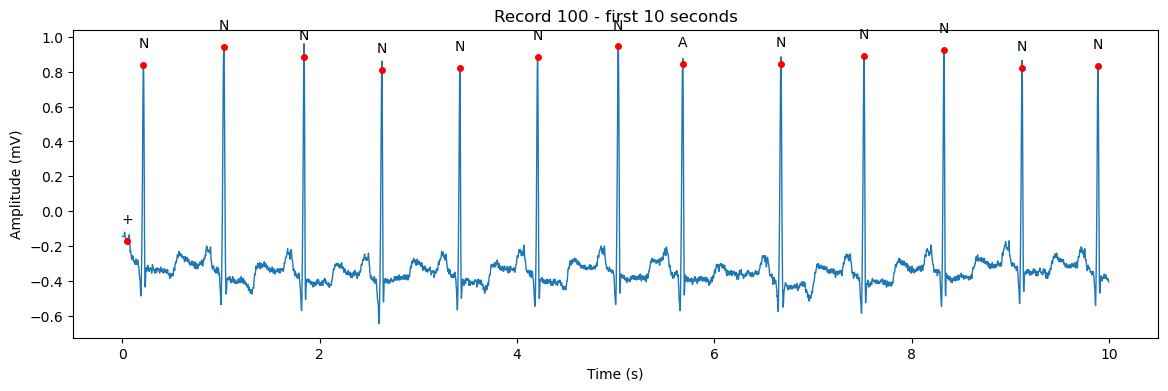

In [3]:
n = 10 * fs
t = np.arange(n) / fs

mask = ann.sample < n
peaks = ann.sample[mask]
symbols = np.array(ann.symbol)[mask]

plt.figure(figsize=(14, 4))
plt.plot(t, signal[:n], lw=1)
plt.plot(peaks / fs, signal[peaks], "ro", ms=4)
for p, s in zip(peaks, symbols):
    plt.text(p / fs, signal[p] + 0.1, s, ha="center")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.title(f"Record {rec_id} - first 10 seconds")
plt.show()

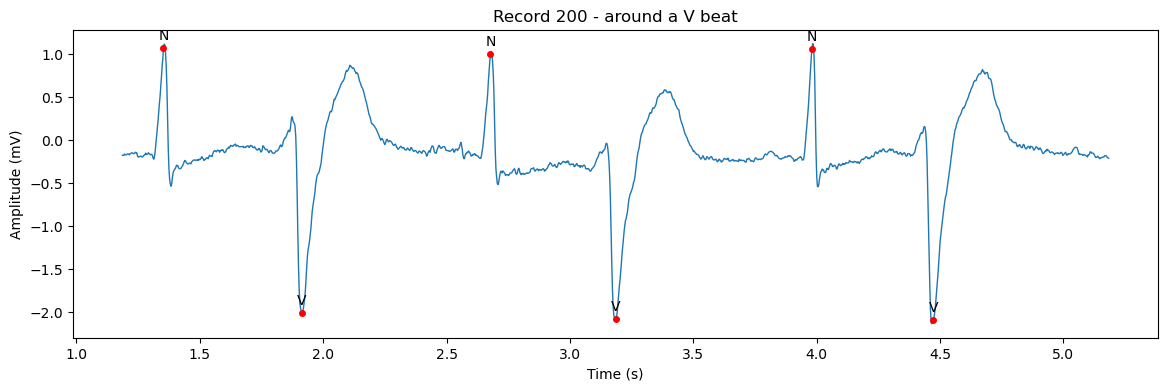

In [4]:
rec_id = "200"
record = wfdb.rdrecord(f"{DATA_DIR}/{rec_id}")
ann = wfdb.rdann(f"{DATA_DIR}/{rec_id}", "atr")
signal = record.p_signal[:, 0]
fs = record.fs

symbols = np.array(ann.symbol)
v_samples = ann.sample[symbols == "V"]
center = v_samples[v_samples > 2 * fs][0]   # اولین V با فاصله‌ی کافی از ابتدای رکورد

lo, hi = center - 2 * fs, center + 2 * fs   # ۲ ثانیه قبل و بعد
t = np.arange(lo, hi) / fs

in_win = (ann.sample >= lo) & (ann.sample < hi)
plt.figure(figsize=(14, 4))
plt.plot(t, signal[lo:hi], lw=1)
for p, s in zip(ann.sample[in_win], symbols[in_win]):
    plt.plot(p / fs, signal[p], "ro", ms=4)
    plt.text(p / fs, signal[p] + 0.1, s, ha="center")
plt.title(f"Record {rec_id} - around a V beat")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()

In [5]:
from collections import Counter

records = sorted(f[:-4] for f in os.listdir(DATA_DIR) if f.endswith(".hea"))
print("تعداد رکوردها:", len(records))

counts = Counter()
for r in records:
    a = wfdb.rdann(f"{DATA_DIR}/{r}", "atr")
    counts.update(a.symbol)

for sym, c in counts.most_common():
    print(f"{sym!r:6} {c}")

تعداد رکوردها: 48
'N'    75052
'L'    8075
'R'    7259
'V'    7130
'/'    7028
'A'    2546
'+'    1291
'f'    982
'F'    803
'~'    616
'!'    472
'"'    437
'j'    229
'x'    193
'a'    150
'|'    132
'E'    106
'J'    83
'Q'    33
'e'    16
'['    6
']'    6
'S'    2
